# 09 · DPO training on top of SFT

**Goal:** teach the SFT model (1) to return `[]` when no tool fits and (2) to stop its most common argument mistakes, **without** losing tool-calling accuracy.

### How DPO works, in one picture
```
for each pair (prompt, chosen, rejected):
    policy    = SFT model + NEW LoRA (trainable)
    reference = SFT model (same weights, LoRA switched off, frozen)

    chosen_reward   = β · [ log P_policy(chosen)   − log P_ref(chosen)   ]
    rejected_reward = β · [ log P_policy(rejected) − log P_ref(rejected) ]

    loss = −log σ(chosen_reward − rejected_reward)
```
The model is pushed to make **chosen more likely and rejected less likely, relative to where SFT started**. The reference keeps it anchored: it only gets credit for *changing* its preferences, and β controls how far it may drift.

### How to run (one GPU run per day)
1. **Stop vLLM** (training needs the whole 6 GB).
2. **`SMOKE_TEST = True` → Run All** (~5 min): 10 steps on the **longest** pairs, then save, merge and test generation. It prints peak VRAM and the full-run time estimate.
3. **`SMOKE_TEST = False` → Run All** and leave it. Resumes from the last checkpoint if it crashes.

## 0 · Setup

In [1]:
import gc, json, sys, hashlib
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
import torch

REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
DATA_DIR = REPO_ROOT / "notebooks" / "data"
sys.path.insert(0, str(REPO_ROOT))
from src.prompts import build_messages

print("Repo:", REPO_ROOT)
print("GPU: ", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none!")

Repo: c:\Users\Swapn\OneDrive\Documents\GitHub\SLM Finetuning
GPU:  NVIDIA GeForce RTX 4050 Laptop GPU


## 1 · Config
The three knobs that matter most:
- **`BETA = 0.1`**: how strongly the model is held to the SFT reference. Higher = safer but learns less, lower = learns more but can drift. 0.1 is the standard starting point.
- **`LEARNING_RATE = 2e-5`**: ~10× lower than SFT (2e-4). DPO *adjusts* behaviour the model already has; big steps break things.
- **`RPO_ALPHA = 1.0`**: adds a normal SFT loss on the **chosen** answer. Plain DPO can lower the probability of *both* answers (it only cares about the gap), which can quietly hurt exact match. This keeps the correct answers likely. ("RPO", Pang et al. 2024.)

**`MAX_LENGTH = 1600`** comes from the length check in 07 (max pair = 1,595 tokens), so nothing is truncated.

In [2]:
SMOKE_TEST = False            # True = ~5 min dry run of everything. False = the real run.

RUN_NAME = "dpo_qwen2.5-0.5b"
SFT_MERGED = REPO_ROOT / "notebooks/outputs/sft_qwen2.5-0.5b/merged"   # the starting point (= reference)
SEED = 3407

# DPO
BETA = 0.1
RPO_ALPHA = 1.0
LEARNING_RATE = 2e-5
NUM_EPOCHS = 2
MAX_LENGTH = 1600            # from 07's token-length check (max 1,595)

# LoRA (new adapter on top of the merged SFT model)
LORA_R, LORA_ALPHA = 16, 32

# batch: each step sees chosen + rejected, and the reference forward pass too -> keep per-device batch at 1
BATCH_SIZE, GRAD_ACCUM = 1, 16      # effective batch = 16 pairs
EVAL_EVERY = 20
SMOKE_STEPS = 10

if SMOKE_TEST:
    RUN_NAME += "_smoke"
OUTPUT_DIR = REPO_ROOT / "notebooks/outputs" / RUN_NAME
ADAPTER_DIR = OUTPUT_DIR / "adapter"
MERGED_DIR = OUTPUT_DIR / "merged"
DPO_DATA = DATA_DIR / "dpo"

for f in ["dpo_train.jsonl", "dpo_val.jsonl"]:
    print(f, hashlib.sha256((DPO_DATA / f).read_bytes()).hexdigest()[:12])
assert SFT_MERGED.exists(), f"missing {SFT_MERGED}"
print(f"{'SMOKE TEST' if SMOKE_TEST else 'REAL RUN'} -> {RUN_NAME}")

dpo_train.jsonl f2a3103100db
dpo_val.jsonl 281c8c88ec21
REAL RUN -> dpo_qwen2.5-0.5b


# Part A · Train

## 2 · Load SFT model (4-bit) + a new LoRA
- We load the **merged SFT model** and put a **fresh** LoRA on it. That gives two models for the price of one:
  - LoRA **on** = the policy (what we train)
  - LoRA **off** = exactly the SFT model = the **reference**. TRL does this automatically (`ref_model=None` + PEFT → `disable_adapter()`), so no second copy in VRAM.
- Unsloth must be imported first (it patches transformers / TRL).

In [3]:
from unsloth import FastLanguageModel, is_bfloat16_supported

model, tokenizer = FastLanguageModel.from_pretrained(
    model_name=str(SFT_MERGED),
    max_seq_length=MAX_LENGTH,
    load_in_4bit=True,
    dtype=None,
)
model = FastLanguageModel.get_peft_model(
    model,
    r=LORA_R,
    lora_alpha=LORA_ALPHA,
    lora_dropout=0.0,
    target_modules=["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"],
    bias="none",
    use_gradient_checkpointing="unsloth",
    random_state=SEED,
)
model.print_trainable_parameters()

🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.


W1016 00:27:58.096000 15404 site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


🦥 Unsloth Zoo will now patch everything to make training faster!
==((====))==  Unsloth 2026.8.4: Fast Qwen2 patching. Transformers: 5.5.0.
   \\   /|    NVIDIA GeForce RTX 4050 Laptop GPU. Num GPUs = 1. Max memory: 5.997 GB. Platform: Windows.
O^O/ \_/ \    Torch: 2.11.0+cu130. CUDA: 8.9. CUDA Toolkit: 13.0. Triton: 3.7.1
\        /    Bfloat16 = TRUE. FA [Xformers = None. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

Unsloth 2026.8.4 patched 24 layers with 24 QKV layers, 24 O layers and 24 MLP layers.


trainable params: 8,798,208 || all params: 502,830,976 || trainable%: 1.7497


## 3 · Data
Each pair becomes **plain strings**: the prompt is Qwen's chat template up to `<|im_start|>assistant\n` (same as SFT and vLLM), chosen/rejected are just the JSON answers. TRL appends `<|im_end|>` to each answer, so they end exactly like the SFT targets.
The **smoke test** uses the longest pairs, so its peak VRAM is the worst case.

In [4]:
from datasets import load_dataset

ds = load_dataset("json", data_files={"train": str(DPO_DATA / "dpo_train.jsonl"),
                                      "validation": str(DPO_DATA / "dpo_val.jsonl")})
print("kinds in train:", pd.Series(ds["train"]["kind"]).value_counts().to_dict())
# Format ourselves -> plain strings, exactly like SFT training saw them:
#   prompt  = chat template up to "<|im_start|>assistant\n"
#   chosen  = the JSON answer only (TRL appends <|im_end|> = eos, so it ends exactly like SFT targets)
# If we pass message lists instead, TRL templates the answer as "JSON<|im_end|>\n" and THEN appends
# another <|im_end|>: a junk token after "\n" that SFT never produced, which swamps the learning signal.
def to_strings(row):
    return {
        "prompt": tokenizer.apply_chat_template(row["prompt"], tokenize=False, add_generation_prompt=True),
        "chosen": row["chosen"][0]["content"],
        "rejected": row["rejected"][0]["content"],
    }
ds = ds.map(to_strings, remove_columns=ds["train"].column_names)
train_ds, val_ds = ds["train"], ds["validation"]

if SMOKE_TEST:
    size = [len(json.dumps(r["prompt"])) + len(json.dumps(r["rejected"])) for r in train_ds]
    longest = sorted(range(len(size)), key=lambda i: size[i], reverse=True)
    train_ds = train_ds.select(longest[: SMOKE_STEPS * BATCH_SIZE * GRAD_ACCUM])
    val_ds = val_ds.select(range(16))
print(f"train: {len(train_ds):,} | val: {len(val_ds):,}")

kinds in train: {'mistake': 1067, 'abstain': 300, 'balance': 300}
train: 1,667 | val: 86


In [5]:
# Force single-process dataset.map: Windows can't spawn ~20 tokenizer workers
# (each one re-imports torch + unsloth), and Unsloth overrides dataset_num_proc.
import datasets
if not getattr(datasets.Dataset.map, "_single_proc", False):
    _orig_map = datasets.Dataset.map
    def _map_single_proc(self, *args, **kwargs):
        kwargs["num_proc"] = None
        return _orig_map(self, *args, **kwargs)
    _map_single_proc._single_proc = True
    datasets.Dataset.map = _map_single_proc
print("dataset.map -> single process")

dataset.map -> single process


## 4 · Trainer
- **`max_prompt_length=None`**: this TRL version defaults to **512** and would cut the tool list off the front of most prompts. We never truncate, and step 5 proves it.
- **`load_best_model_at_end`** on eval loss: if DPO starts drifting in epoch 2, the best checkpoint is kept anyway.
- **`dataset_num_proc=1`**: multiprocess tokenization can hang in Windows notebooks; 1.7k rows is fast anyway.

In [6]:
try:                                   # older Unsloth needs this; newer versions patch automatically
    from unsloth import PatchDPOTrainer
    PatchDPOTrainer()
except Exception:
    pass
from trl.trainer.dpo_config import DPOConfig
from trl.trainer.dpo_trainer import DPOTrainer

eval_every = 5 if SMOKE_TEST else EVAL_EVERY
args = DPOConfig(
    output_dir=str(OUTPUT_DIR),
    num_train_epochs=NUM_EPOCHS,
    max_steps=SMOKE_STEPS if SMOKE_TEST else -1,
    per_device_train_batch_size=BATCH_SIZE,
    per_device_eval_batch_size=BATCH_SIZE,
    gradient_accumulation_steps=GRAD_ACCUM,

    beta=BETA,
    loss_type="sigmoid",               # standard DPO loss
    rpo_alpha=RPO_ALPHA,

    learning_rate=LEARNING_RATE,
    lr_scheduler_type="cosine",
    warmup_steps=0.1,                  # < 1 = ratio of total steps (same style as 04)
    weight_decay=0.0,
    optim="adamw_8bit",
    bf16=is_bfloat16_supported(),
    fp16=not is_bfloat16_supported(),

    max_length=MAX_LENGTH,
    max_prompt_length=None,            # !!! default 512 would truncate the tool list
    max_completion_length=None,

    logging_steps=1 if SMOKE_TEST else 5,
    eval_strategy="steps",
    eval_steps=eval_every,
    save_strategy="steps",
    save_steps=eval_every,
    save_total_limit=2,
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    greater_is_better=False,

    dataset_num_proc=1,
    seed=SEED,
    report_to="none",
)

trainer = DPOTrainer(
    model=model,
    ref_model=None,                    # PEFT model -> reference = adapter switched off
    args=args,
    train_dataset=train_ds,
    eval_dataset=val_ds,
    processing_class=tokenizer,
)

Extracting prompt in train dataset:   0%|          | 0/1667 [00:00<?, ? examples/s]

Applying chat template to train dataset:   0%|          | 0/1667 [00:00<?, ? examples/s]

Tokenizing train dataset:   0%|          | 0/1667 [00:00<?, ? examples/s]

Extracting prompt in eval dataset:   0%|          | 0/86 [00:00<?, ? examples/s]

Applying chat template to eval dataset:   0%|          | 0/86 [00:00<?, ? examples/s]

Tokenizing eval dataset:   0%|          | 0/86 [00:00<?, ? examples/s]

## 5 · Checks before spending GPU time
1. **Nothing truncated:** prompt + longest answer ≤ `MAX_LENGTH` for every pair.
2. **What the model actually sees:** decode one tokenized pair. The prompt must end with `<|im_start|>assistant\n` (with the full tool list above it) and chosen/rejected must be just the JSON answers.

In [7]:
td = trainer.train_dataset
print("tokenized columns:", td.column_names)
lens = [len(p) + max(len(c), len(r)) for p, c, r in
        zip(td["prompt_input_ids"], td["chosen_input_ids"], td["rejected_input_ids"])]
print(f"longest pair: {max(lens)} tokens (limit {MAX_LENGTH})")
assert max(lens) <= MAX_LENGTH, "some pairs would be truncated: raise MAX_LENGTH"
assert len(td) == len(train_ds), "rows were dropped"

row = td[0]
prompt_txt = tokenizer.decode(row["prompt_input_ids"])
print("PROMPT (last 150 chars):", repr(prompt_txt[-150:]))
print("CHOSEN:  ", repr(tokenizer.decode(row["chosen_input_ids"])))
print("REJECTED:", repr(tokenizer.decode(row["rejected_input_ids"])))
assert prompt_txt.rstrip().endswith("<|im_start|>assistant"), "prompt doesn't end at the assistant turn"
assert "Available tools" in prompt_txt, "tool list missing from the prompt"
for key in ["chosen_input_ids", "rejected_input_ids"]:
    for r in td.select(range(min(200, len(td)))):
        txt = tokenizer.decode(r[key])
        assert txt.endswith("<|im_end|>") and txt.count("<|im_end|>") == 1 and "\n<|im_end|>" not in txt, \
            f"{key} should be JSON + one <|im_end|>, got {txt[-60:]!r}"
print("✅ checks passed")

tokenized columns: ['prompt', 'prompt_input_ids', 'chosen_input_ids', 'rejected_input_ids']
longest pair: 1594 tokens (limit 1600)
PROMPT (last 150 chars): 'culate the standard deviation for the list of numbers [4.2, 5.6, 7.8, 9.1]\n\nReturn the required tool call(s) as JSON.<|im_end|>\n<|im_start|>assistant\n'
CHOSEN:   '[{"name": "expand_around_center", "arguments": {"s": "abcba", "left": 1, "right": 3}}, {"name": "std_deviation", "arguments": {"numbers": [4.2, 5.6, 7.8, 9.1]}}]<|im_end|>'
REJECTED: '[{"name": "expand_around_center", "arguments": {"s": "abcba", "left": 1, "right": 3}}, {"name": "calculate_standard_deviation", "arguments": {"numbers": [4.2, 5.6, 7.8, 9.1]}}]<|im_end|>'
✅ checks passed


## 6 · Train
Plug the laptop in and set sleep to "Never". On a crash, just Run All again: it resumes from the last checkpoint.

**What to watch in the log** (all are on the *gap* between chosen and rejected):
| metric | healthy |
|---|---|
| `rewards/accuracies` | climbs from ~0.5 toward 0.8–1.0 (how often chosen beats rejected) |
| `rewards/margins` | grows above 0 |
| `rewards/chosen` | around 0 or positive (RPO keeps it up) |
| `rewards/rejected` | goes negative (mistakes become less likely) |
| `eval_loss` | falls from ~0.69 (= log 2, "no preference yet") |

In [8]:
from transformers.trainer_utils import get_last_checkpoint

last_ckpt = get_last_checkpoint(str(OUTPUT_DIR)) if OUTPUT_DIR.exists() else None
print("Resuming from", last_ckpt or "scratch")

torch.cuda.reset_peak_memory_stats()
result = trainer.train(resume_from_checkpoint=last_ckpt)
peak_vram = torch.cuda.max_memory_allocated() / 1024**3

model.save_pretrained(str(ADAPTER_DIR))
tokenizer.save_pretrained(str(ADAPTER_DIR))
(OUTPUT_DIR / "train_log.json").write_text(json.dumps(trainer.state.log_history, indent=2))

print(f"\nTrain loss:     {result.training_loss:.4f}")
print(f"Best eval loss: {trainer.state.best_metric}  ({trainer.state.best_model_checkpoint})")
print(f"Runtime:        {result.metrics['train_runtime'] / 60:.1f} min")
print(f"Peak VRAM:      {peak_vram:.2f} GB of 6")
if SMOKE_TEST:
    full_steps = NUM_EPOCHS * -(-len(ds["train"]) // (BATCH_SIZE * GRAD_ACCUM))
    est_min = result.metrics["train_runtime"] / SMOKE_STEPS * full_steps / 60
    print(f"\n⏱  Full run: {full_steps} steps, ~{est_min:.0f} min + evals (upper bound: smoke used the longest pairs)")
    if peak_vram > 5.5:
        print("⚠️  Close to 6 GB. Lower MAX_LENGTH is not an option (truncation); close other GPU apps.")

The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'bos_token_id': None}.


Resuming from scratch


==((====))==  Unsloth - 2x faster free finetuning | Num GPUs used = 1
   \\   /|    Num examples = 1,667 | Num Epochs = 2 | Total steps = 210
O^O/ \_/ \    Batch size per device = 1 | Gradient accumulation steps = 16
\        /    Data Parallel GPUs = 1 | Total batch size (1 x 16 x 1) = 16
 "-____-"     Trainable parameters = 8,798,208 of 502,830,976 (1.75% trained)
`use_return_dict` is deprecated! Use `return_dict` instead!


Unsloth: Will smartly offload gradients to save VRAM!
Unsloth: Double buffering enabled (parallel H2D + compute) for backward pass.


Step,Training Loss,Validation Loss,Runtime,Samples Per Second,Steps Per Second,Rewards/chosen,Rewards/rejected,Rewards/accuracies,Rewards/margins,Logps/chosen,Logps/rejected,Logits/chosen,Logits/rejected,Nll Loss
20,1.146763,1.022744,50.147900,1.715000,1.715000,0.127717,0.130801,0.488372,-0.003084,-5.318350,-6.825752,-1.291018,-1.226393,0.277908
40,0.930063,0.875311,48.658200,1.767000,1.767000,0.184342,0.153941,0.534884,0.030402,-4.752097,-6.594351,-1.200588,-1.176504,0.141774
60,0.871756,0.799763,50.061300,1.718000,1.718000,0.194788,0.070044,0.569767,0.124744,-4.647640,-7.433320,-1.227460,-1.213208,0.105514
80,0.751154,0.727331,53.879600,1.596000,1.596000,0.194662,-0.087230,0.558140,0.281892,-4.648896,-9.006056,-1.294439,-1.280371,0.098996
100,0.690892,0.686297,52.463100,1.639000,1.639000,0.187434,-0.279123,0.744186,0.466558,-4.721176,-10.924989,-1.331679,-1.374008,0.136737
120,0.526866,0.619812,48.439600,1.775000,1.775000,0.185815,-0.508521,0.744186,0.694336,-4.737367,-13.218963,-1.349729,-1.419551,0.119703
140,0.565193,0.565440,48.392100,1.777000,1.777000,0.183942,-0.746001,0.709302,0.929943,-4.756103,-15.593768,-1.348598,-1.413079,0.093413
160,0.548397,0.555414,54.615100,1.575000,1.575000,0.188605,-0.829946,0.744186,1.018552,-4.709466,-16.433222,-1.339326,-1.413500,0.091645
180,0.482583,0.552366,50.856900,1.691000,1.691000,0.189095,-0.858389,0.744186,1.047484,-4.704567,-16.717644,-1.330020,-1.408305,0.091366
200,0.583820,0.552150,55.452600,1.551000,1.551000,0.188484,-0.874256,0.732558,1.062739,-4.710682,-16.876314,-1.327525,-1.406741,0.091566


Unsloth: Restored added_tokens_decoder metadata in c:\Users\Swapn\OneDrive\Documents\GitHub\SLM Finetuning\notebooks\outputs\dpo_qwen2.5-0.5b\checkpoint-20\tokenizer_config.json.
Unsloth: Restored added_tokens_decoder metadata in c:\Users\Swapn\OneDrive\Documents\GitHub\SLM Finetuning\notebooks\outputs\dpo_qwen2.5-0.5b\checkpoint-40\tokenizer_config.json.
Unsloth: Restored added_tokens_decoder metadata in c:\Users\Swapn\OneDrive\Documents\GitHub\SLM Finetuning\notebooks\outputs\dpo_qwen2.5-0.5b\checkpoint-60\tokenizer_config.json.
Unsloth: Restored added_tokens_decoder metadata in c:\Users\Swapn\OneDrive\Documents\GitHub\SLM Finetuning\notebooks\outputs\dpo_qwen2.5-0.5b\checkpoint-80\tokenizer_config.json.
Unsloth: Restored added_tokens_decoder metadata in c:\Users\Swapn\OneDrive\Documents\GitHub\SLM Finetuning\notebooks\outputs\dpo_qwen2.5-0.5b\checkpoint-100\tokenizer_config.json.
Unsloth: Restored added_tokens_decoder metadata in c:\Users\Swapn\OneDrive\Documents\GitHub\SLM Finetuni


Train loss:     0.7578
Best eval loss: 0.5511161684989929  (c:\Users\Swapn\OneDrive\Documents\GitHub\SLM Finetuning\notebooks\outputs\dpo_qwen2.5-0.5b\checkpoint-210)
Runtime:        199.4 min
Peak VRAM:      7.79 GB of 6


### Training curves

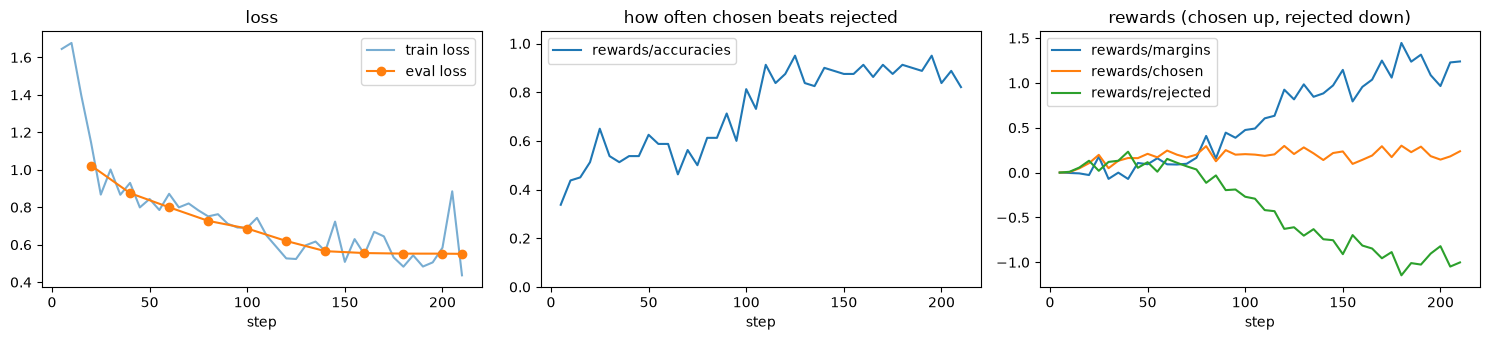

In [9]:
log = pd.DataFrame(trainer.state.log_history)
cols = ["rewards/accuracies", "rewards/margins", "rewards/chosen", "rewards/rejected"]
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
log.dropna(subset=["loss"]).plot(x="step", y="loss", ax=axes[0], label="train loss", alpha=0.6)
if "eval_loss" in log:
    log.dropna(subset=["eval_loss"]).plot(x="step", y="eval_loss", ax=axes[0], marker="o", label="eval loss")
train_log = log.dropna(subset=["rewards/accuracies"]) if "rewards/accuracies" in log else pd.DataFrame()
if len(train_log):
    train_log.plot(x="step", y=["rewards/accuracies"], ax=axes[1], ylim=(0, 1.05))
    train_log.plot(x="step", y=["rewards/margins", "rewards/chosen", "rewards/rejected"], ax=axes[2])
for ax, t in zip(axes, ["loss", "how often chosen beats rejected", "rewards (chosen up, rejected down)"]):
    ax.set_title(t)
plt.tight_layout(); plt.show()

# Part B · Merge + quick sanity check
⚠️ **Restart the kernel first**, run sections 0 and 1, then Part B. Unsloth patches Qwen2 globally while training, so a plain transformers model in the same kernel crashes. Part B only needs the saved adapter.

## 7 · Merge the DPO adapter into the SFT model (bf16)
Same recipe as SFT: load the **bf16** merged SFT model with plain transformers, apply the DPO adapter, merge, save. The result is a normal HF model that vLLM, 05 (HF export) and 06 (Ollama) can use directly.

In [3]:
import sys
assert "unsloth" not in sys.modules, (
    "Unsloth is loaded in this kernel and has patched Qwen2, so a plain model crashes (no 'apply_qkv'). "
    "Restart the kernel, run sections 0 and 1, then Part B.")
from peft import PeftModel
from transformers import AutoModelForCausalLM, AutoTokenizer

trainer = model = None
gc.collect(); torch.cuda.empty_cache()

tok = AutoTokenizer.from_pretrained(str(SFT_MERGED))
base = AutoModelForCausalLM.from_pretrained(str(SFT_MERGED), dtype=torch.bfloat16, device_map="cuda")
dpo = PeftModel.from_pretrained(base, str(ADAPTER_DIR)).merge_and_unload()
dpo.eval()
dpo.save_pretrained(str(MERGED_DIR))
tok.save_pretrained(str(MERGED_DIR))
print("merged DPO model ->", MERGED_DIR)

W1015 19:45:21.962000 12684 site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

merged DPO model -> c:\Users\Swapn\OneDrive\Documents\GitHub\SLM Finetuning\notebooks\outputs\dpo_qwen2.5-0.5b_smoke\merged


## 8 · Sanity check: a few greedy answers
Not the eval (that's 08 via vLLM), just a quick look that the model still writes valid tool calls **and** now abstains:
- a normal test question → should still call the right tool
- 2 questions from the frozen abstain set → hopefully `[]`
- the live failure from the gateway: "Tell me a joke" with only `get_weather` → hopefully `[]`

In [4]:
EVAL = DATA_DIR / "eval"
test_q = json.loads(open(EVAL / "test_v1.jsonl", encoding="utf-8").readline())
abst = [json.loads(l) for l in open(EVAL / "abstain_v1.jsonl", encoding="utf-8")][:2]
joke = {"query": "Tell me a joke",
        "tools": [{"name": "get_weather", "description": "Get the current weather for a city.",
                   "parameters": {"city": {"description": "Name of the city.", "type": "str"}}}]}

def answer(record):
    text = tok.apply_chat_template(build_messages(record), tokenize=False, add_generation_prompt=True)
    enc = tok(text, return_tensors="pt", add_special_tokens=False).to(dpo.device)
    with torch.inference_mode():
        out = dpo.generate(**enc, max_new_tokens=200, do_sample=False)
    return tok.decode(out[0, enc["input_ids"].shape[1]:], skip_special_tokens=True)

for name, rec in [("normal", test_q), ("abstain-1", abst[0]), ("abstain-2", abst[1]), ("joke", joke)]:
    print(f"\n[{name}] {rec['query'][:90]}")
    if name == "normal":
        print("  gold:", json.dumps(rec["answers"]))
    print("  DPO: ", answer(rec))


[normal] Fetch details for product 456789 with locale 'es_ES'.
  gold: [{"name": "product_id", "arguments": {"is_id": 456789, "locale": "es_ES"}}]
  DPO:  [{"name": "product_id", "arguments": {"is_id": 456789, "locale": "es_ES"}}]

[abstain-1] Can you fetch the latest orders for my email 'john.doe@example.com' with a status of 'proc
  DPO:  [{"name": "posts", "arguments": {"creator_id": 12345, "status": "processing"}}, {"name": "orders", "arguments": {"order_id": "12345"}}, {"name": "categories", "arguments": {"locale": "US"}}]

[abstain-2] What is the smallest number in the list: 10, 20, 30, 40, and 50?
  DPO:  [{"name": "numerology", "arguments": {"n": "10"}}, {"name": "numerology", "arguments": {"n": "20"}}, {"name": "numerology", "arguments": {"n": "30"}}, {"name": "numerology", "arguments": {"n": "40"}}, {"name": "numerology", "arguments": {"n": "50"}}]

[joke] Tell me a joke
  DPO:  [{"name": "get_weather", "arguments": {"city": "New York"}}]


## 9 · Next: the real eval (notebook 08)
Serve the DPO model in WSL (same flags as `~/start_vllm.sh`, new path + name):
```bash
vllm serve "/mnt/c/Users/Swapn/OneDrive/Documents/GitHub/SLM Finetuning/notebooks/outputs/dpo_qwen2.5-0.5b/merged" \
  --served-model-name dpo-toolcaller --max-model-len 4096 --gpu-memory-utilization 0.7 --generation-config vllm
```
Then in **08** set `RUN_NAME = "dpo"`, `MODEL = "dpo-toolcaller"` → Run All. Step 7 there prints SFT vs DPO side by side.

**Success =** abstain rate ≫ 0%, test exact match ≈ 81% (not below ~80), over-abstain ≈ 0%.